In [1]:
import pandas as pd 
import numpy as np
df= pd.read_csv("cs-training.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (150000, 12)

Column Names:
['Unnamed: 0', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 n

In [3]:
# Check the target column distribution
print(df['SeriousDlqin2yrs'].value_counts())

print("\nPercentage distribution:")
print(df['SeriousDlqin2yrs'].value_counts(normalize=True) * 100)

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Percentage distribution:
SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64


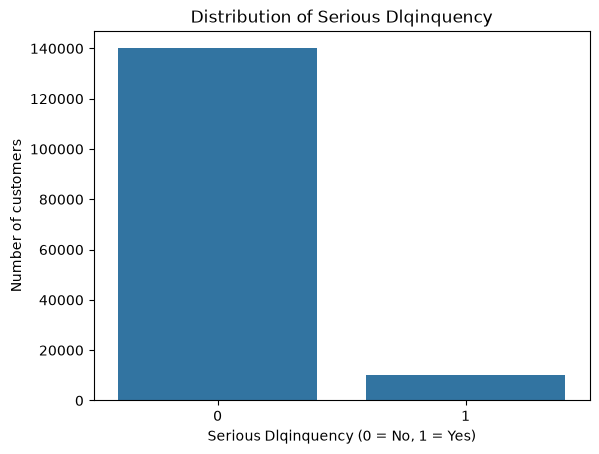

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='SeriousDlqin2yrs')

plt.title('Distribution of Serious Dlqinquency')
plt.xlabel('Serious Dlqinquency (0 = No, 1 = Yes)')
plt.ylabel('Number of customers')
plt.savefig('figures/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# checking missing values
print("missing values in each column:")
print(df.isnull().sum())

# check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

missing values in each column:
Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

Number of duplicate rows: 0


In [7]:
from sklearn.model_selection import train_test_split

# Remove the unnecessary row-index column
df = df.drop(columns=["Unnamed: 0"])

# Separate target and features
X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fill missing values using training data medians
for col in ["MonthlyIncome", "NumberOfDependents"]:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features shape: (120000, 10)
Testing features shape: (30000, 10)

Missing values in training data: 0
Missing values in testing data: 0

Training target distribution:
SeriousDlqin2yrs
0    111979
1      8021
Name: count, dtype: int64

Testing target distribution:
SeriousDlqin2yrs
0    27995
1     2005
Name: count, dtype: int64


In [12]:
print(X_train.shape , X_test.shape)
print(X_train.isna().sum(), X_test.isna().sum().sum())
print(y_train.mean(), y_test.mean())

(120000, 10) (30000, 10)
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64 0
0.06684166666666666 0.06683333333333333


In [11]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,120000.0,6.128916,253.361490,0.0,0.029593,0.153318,0.557832,50708.0
age,120000.0,52.287842,14.771274,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.420075,4.182138,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,120000.0,352.271245,2093.709509,0.0,0.175330,0.366194,0.860833,329664.0
MonthlyIncome,120000.0,6402.622458,13037.680488,0.0,3900.000000,5390.000000,7400.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,120000.0,8.465692,5.161693,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,120000.0,0.264942,4.158242,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,120000.0,1.018167,1.133055,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.239858,4.144569,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,120000.0,0.737592,1.107299,0.0,0.000000,0.000000,1.000000,20.0


In [16]:
# Remove rows with invalid ages (below 18 or above 100)
bad_train = (X_train["age"] < 18) | (X_train["age"] > 100)
bad_test = (X_test["age"] < 18) | (X_test["age"] > 100)
print("Rows removed (train, test):", bad_train.sum(), bad_test.sum())

X_train, y_train = X_train[~bad_train], y_train[~bad_train]
X_test, y_test = X_test[~bad_test], y_test[~bad_test]

Rows removed (train, test): 0 0


In [17]:
# Values like 96 and 98 are placeholder codes, so cap the counts at 20
late_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
             "NumberOfTimes90DaysLate",
             "NumberOfTime60-89DaysPastDueNotWorse"]
for c in late_cols:
    X_train[c] = X_train[c].clip(upper=20)
    X_test[c] = X_test[c].clip(upper=20)

In [18]:
# The cap is computed on the training set only and applied to both sets (avoids data leakage)
for c in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]:
    cap = X_train[c].quantile(0.99)
    print(c, "cap =", round(cap, 2))
    X_train[c] = X_train[c].clip(upper=cap)
    X_test[c] = X_test[c].clip(upper=cap)

RevolvingUtilizationOfUnsecuredLines cap = 1.09
DebtRatio cap = 4977.0
MonthlyIncome cap = 23000.0


In [20]:
print(X_train.describe().T[["min", "50%", "max"]])
print(y_train.mean(), y_test.mean())

                                       min          50%           max
RevolvingUtilizationOfUnsecuredLines   0.0     0.153361      1.094476
age                                   21.0    52.000000     99.000000
NumberOfTime30-59DaysPastDueNotWorse   0.0     0.000000     20.000000
DebtRatio                              0.0     0.366194   4977.000000
MonthlyIncome                          0.0  5390.000000  23000.000000
NumberOfOpenCreditLinesAndLoans        0.0     8.000000     58.000000
NumberOfTimes90DaysLate                0.0     0.000000     20.000000
NumberRealEstateLoansOrLines           0.0     1.000000     54.000000
NumberOfTime60-89DaysPastDueNotWorse   0.0     0.000000     20.000000
NumberOfDependents                     0.0     0.000000     20.000000
0.06683778918594573 0.06684670267386811


In [21]:
import os
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

#combine features and target for saving
pd.concat([X_train, y_train], axis=1).to_csv("data/train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv("data/test.csv", index=False)

#check the saved files
print(pd.read_csv("data/train.csv").shape)

(119992, 11)


In [22]:
print(X_train["age"].min(), X_train["age"].max())
print(X_test["age"].min(), X_test["age"].max())

21 99
21 99


In [23]:
print(pd.read_csv("data/train.csv").shape)
print(pd.read_csv("data/test.csv").shape)
print(pd.read_csv("data/train.csv")["SeriousDlqin2yrs"].mean())
print(pd.read_csv("data/test.csv")["SeriousDlqin2yrs"].mean())

(119992, 11)
(29994, 11)
0.06683778918594573
0.06684670267386811


In [1]:
import os, sys
print(sys.executable)
print(os.getcwd())
print(os.listdir("."))

/usr/local/bin/python3
/Users/riyabisht/Desktop/CREDIT-risk-research
['requirements.txt', 'member1_data.ipynb', 'README.md', '.gitignore', 'figures', '.git', '.vscode', 'data']


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

train = pd.read_csv("data/train.csv")
summary = train.drop(columns=["SeriousDlqin2yrs"]).describe().T[["mean", "min", "50%", "max"]]
summary = summary.round(2)
summary.to_csv("figures/feature_summary.csv")
print(summary)

ModuleNotFoundError: No module named 'pandas'

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

train = pd.read_csv("data/train.csv")
summary = train.drop(columns=["SeriousDlqin2yrs"]).describe().T[["mean", "min", "50%", "max"]]
summary = summary.round(2)
summary.to_csv("figures/feature_summary.csv")
print(summary)

ModuleNotFoundError: No module named 'pandas'

In [4]:
%pip install pandas matplotlib seaborn

  Using cached matplotlib-3.11.2-cp313-cp313-macosx_10_13_x86_64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached numpy-2.5.4-cp313-cp313-macosx_14_0_x86_64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp313-cp313-macosx_10_13_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp313-cp313-macosx_10_13_x86_64.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-macosx_10_13_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp313-cp313-macosx_10_13_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 4.5 MB/s  0:00:02m0:00:0100:01
Using cached matplotlib-3.11.2-cp313-cp313-macosx_10_13_x86_64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp313-cp313-macosx_10_13_x86_64.whl (297 kB)
Using c

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)

train = pd.read_csv("data/train.csv")
summary = train.drop(columns=["SeriousDlqin2yrs"]).describe().T[["mean", "min", "50%", "max"]]
summary = summary.round(2)
summary.to_csv("figures/feature_summary.csv")
print(summary)

                                         mean   min      50%       max
RevolvingUtilizationOfUnsecuredLines     0.32   0.0     0.15      1.09
age                                     52.29  21.0    52.00     99.00
NumberOfTime30-59DaysPastDueNotWorse     0.28   0.0     0.00     20.00
DebtRatio                              315.91   0.0     0.37   4977.00
MonthlyIncome                         6133.42   0.0  5390.00  23000.00
NumberOfOpenCreditLinesAndLoans          8.47   0.0     8.00     58.00
NumberOfTimes90DaysLate                  0.13   0.0     0.00     20.00
NumberRealEstateLoansOrLines             1.02   0.0     1.00     54.00
NumberOfTime60-89DaysPastDueNotWorse     0.10   0.0     0.00     20.00
NumberOfDependents                       0.74   0.0     0.00     20.00


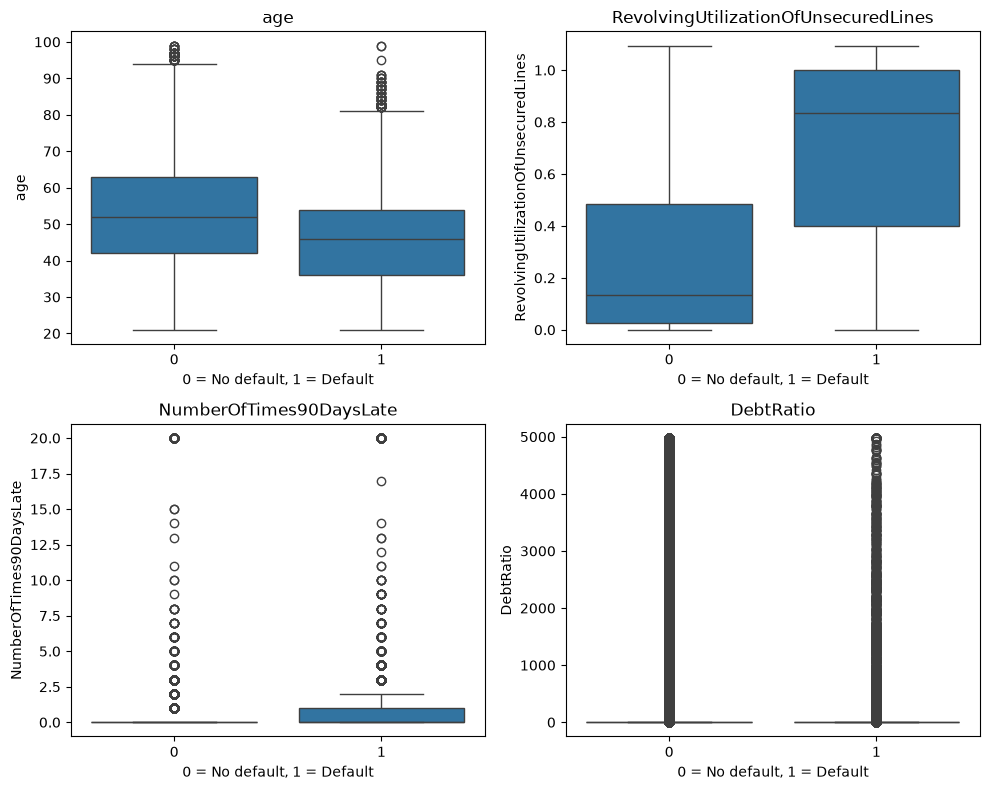

In [7]:
features = ["age", "RevolvingUtilizationOfUnsecuredLines",
            "NumberOfTimes90DaysLate", "DebtRatio"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, f in zip(axes.ravel(), features):
    sns.boxplot(x="SeriousDlqin2yrs", y=f, data=train, ax=ax)
    ax.set_title(f)
    ax.set_xlabel("0 = No default, 1 = Default")
plt.tight_layout()
plt.savefig("figures/default_vs_nodefault.png", dpi=300, bbox_inches="tight")
plt.show()

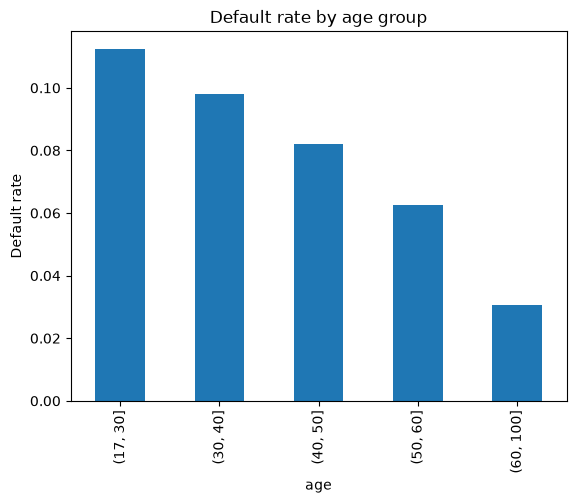

In [8]:
age_group = pd.cut(train["age"], bins=[17, 30, 40, 50, 60, 100])
train.groupby(age_group, observed=True)["SeriousDlqin2yrs"].mean().plot(kind="bar")
plt.ylabel("Default rate")
plt.title("Default rate by age group")
plt.savefig("figures/default_rate_by_age.png", dpi=300, bbox_inches="tight")
plt.show()

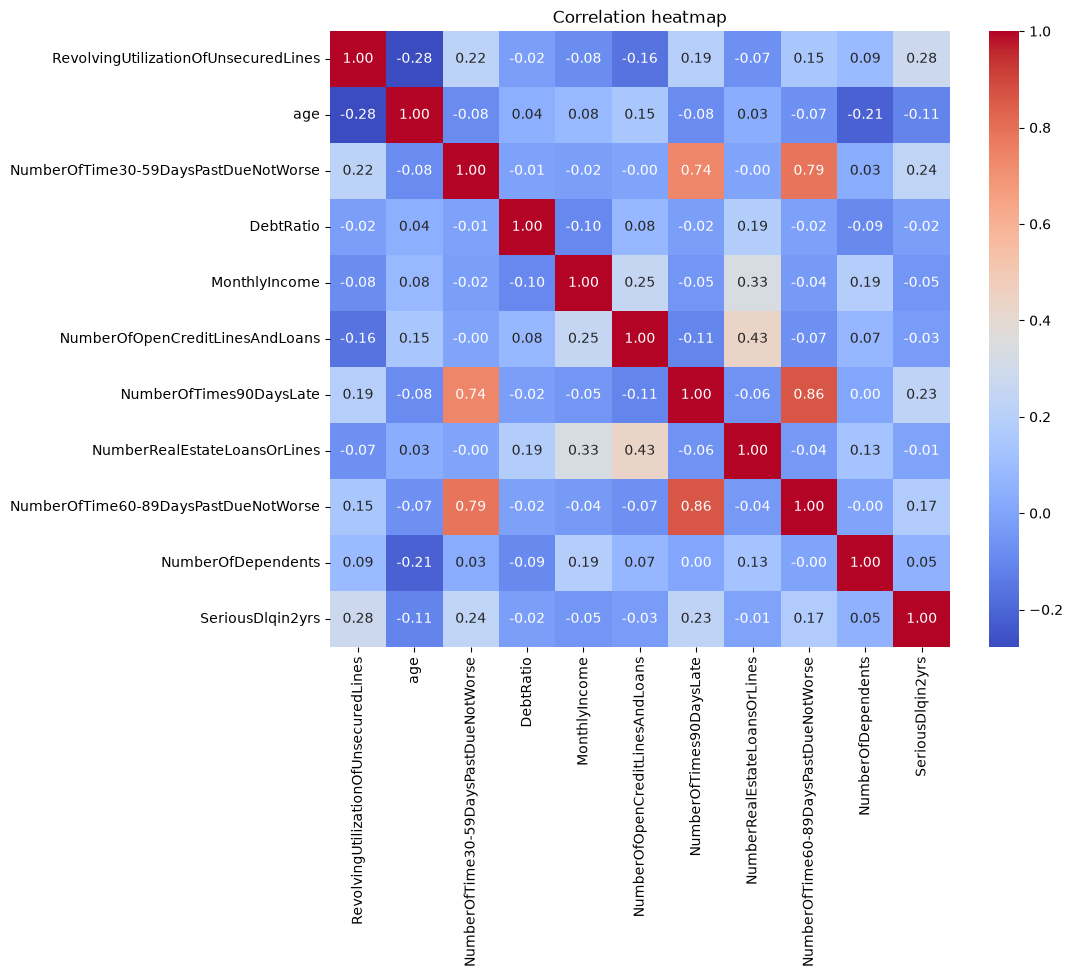

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.savefig("figures/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()